# 01. Phân tích Dữ liệu Khám phá (EDA) & Khung Tiền xử lý Đa phương thức (Tuần 2)

**Học phần:** Máy học nâng cao (*Advanced Machine Learning*) – Trường ĐH Công nghệ Thông tin, ĐHQG-HCM (UIT)  
**Giảng viên hướng dẫn:** ThS./TS. Đặng Việt Dũng  
**Phụ trách chính Notebook:** Hoàng Cao Sơn (MSSV: `25730061` – *Data Engineering & Explainable AI*)  
**Nhóm thực hiện:** Trần Hoàng Hôn, Nguyễn Duy Khang, Phạm Thành Trung, Vũ Văn Duy, Hoàng Cao Sơn

---

> **Ghi chú Minh bạch Học thuật (Data Provenance & Transparency Notice – Tuần 2):**
> - **Dữ liệu thật (Real Datasets):** Các bộ dữ liệu gốc dung lượng lớn (**NTHU-DDD**, **Roboflow Weapons**, **WESAD 15 đối tượng**) và video/ảnh thực địa đường phố TP.HCM (`data/raw/local_samples/`) hiện **chưa được tải/quay thật trên ổ đĩa** (0 ảnh thực địa thật).
> - **Dữ liệu chạy kiểm thử trong Notebook này:** Toàn bộ biểu đồ thực nghiệm dưới đây được trích xuất từ **dữ liệu tổng hợp kiểm thử pipeline (Synthetic / Pilot Dry-Run Data, `is_synthetic=True`)** gồm:
>   1. **50 mẫu thử nghiệm nón bảo hiểm TP.HCM (`data/raw/local_samples_synthetic/`)** mô phỏng 5 loại mũ bảo hiểm Việt Nam và 4 điều kiện chiếu sáng theo đúng phân bố mục tiêu $70\% : 20\% : 10\%$.
>   2. **60 mẫu kiểm thử nhánh Thị giác (`data/raw/vision/`)** của Nguyễn Duy Khang.
>   3. **15 chuỗi nhịp tim 1 Hz WESAD tổng hợp (`data/raw/bio/hr_csv_synthetic/`, $9.300$ giây)** của Phạm Thành Trung.
> - Các thống kê tổng hợp này dùng để **xác thực tính đúng đắn của pipeline nạp dữ liệu, kiểm tra phân tầng nhãn và chuẩn bị cho tiền xử lý Tuần 3**, tuyệt đối không diễn giải như kết quả khám phá khoa học trên người thật.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image

# Đảm bảo import được package `src` dù chạy notebook từ thư mục `notebooks/` hay thư mục gốc
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.download_bio import SYNTHETIC_DIR as BIO_SYNTH_PKL_DIR, generate_synthetic_wesad
from src.data.download_vision import check_dataset_status, generate_sample_vision_data
from src.data.local_samples import (
    REAL_LOCAL_SAMPLES_DIR,
    SYNTHETIC_LOCAL_SAMPLES_DIR,
    check_local_samples_status,
    generate_synthetic_local_pilot,
    validate_local_samples,
)
from src.data.parse_wesad import RAW_BIO_DIR, parse_directory
from src.utils.env_check import set_global_seed

set_global_seed(42)
sns.set_theme(style="whitegrid", palette="deep")
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root : {PROJECT_ROOT}")
print(f"Figures dir  : {FIGURES_DIR}")

Project root : D:\Trí tuệ nhân tạo\HK3\Máy học nâng cao\Đồ án
Figures dir  : D:\Trí tuệ nhân tạo\HK3\Máy học nâng cao\Đồ án\reports\figures


## 1. Kiểm kê Hiện trạng Kho Dữ liệu & Khởi tạo Tự động Mẫu Pilot (Auto-Bootstrap)

Để mọi thành viên trong nhóm có thể chạy lại (*Reproduce*) Notebook này ngay sau khi `git clone` (vì `data/raw/*` được loại trừ khỏi Git theo quy tắc quản trị dữ liệu lớn), ô mã dưới đây kiểm tra trạng thái dữ liệu thực tế và tự động sinh bộ mẫu synthetic/pilot nếu thư mục cục bộ đang trống.

In [2]:
# 1. Kiểm tra nhánh Vision (Khang)
vis_status = check_dataset_status()
if sum(v["image_count"] for v in vis_status.values()) == 0:
    generate_sample_vision_data(num_samples_per_class=15)
    vis_status = check_dataset_status()

# 2. Kiểm tra 50 mẫu Pilot Nón bảo hiểm TP.HCM (Sơn)
local_status = check_local_samples_status()
if not local_status["synthetic_manifest_exists"]:
    generate_synthetic_local_pilot(num_samples=50, seed=42)
    local_status = check_local_samples_status()

pilot_val = validate_local_samples(SYNTHETIC_LOCAL_SAMPLES_DIR)
pilot_df = pd.read_csv(SYNTHETIC_LOCAL_SAMPLES_DIR / "manifest.csv")

# 3. Kiểm tra nhánh Sinh trắc học WESAD 1 Hz (Trung)
bio_csv_dir = RAW_BIO_DIR / "hr_csv_synthetic"
if not bio_csv_dir.exists() or len(list(bio_csv_dir.glob("S*.csv"))) < 15:
    generate_synthetic_wesad(BIO_SYNTH_PKL_DIR, seed=2026)
    parse_directory(BIO_SYNTH_PKL_DIR, bio_csv_dir, source="synthetic")

bio_frames = [pd.read_csv(p) for p in sorted(bio_csv_dir.glob("S*.csv"))]
bio_df = pd.concat(bio_frames, ignore_index=True)

inventory_summary = pd.DataFrame(
    [
        {
            "Phân hệ": "Vision Benchmark (NTHU + Roboflow + Local stub)",
            "Nguồn hiện tại": "Synthetic dry-run",
            "Số lượng mẫu": sum(v["image_count"] for v in vis_status.values()),
            "Đơn vị": "ảnh RGB 160x160",
            "Dữ liệu thật đã nạp": False,
        },
        {
            "Phân hệ": "Local TP.HCM Helmet Pilot (5 loại nón, 10 tài xế)",
            "Nguồn hiện tại": "Synthetic pilot (manifest.csv)",
            "Số lượng mẫu": pilot_val["valid_images"],
            "Đơn vị": "ảnh RGB 160x160",
            "Dữ liệu thật đã nạp": local_status["real_field_data_collected"],
        },
        {
            "Phân hệ": "Bio-Signal WESAD 1 Hz (15 đối tượng S2..S17)",
            "Nguồn hiện tại": "Synthetic BVP -> 1 Hz HR",
            "Số lượng mẫu": int(bio_df["is_valid"].sum()),
            "Đơn vị": f"giây hợp lệ / {len(bio_df)} giây tổng",
            "Dữ liệu thật đã nạp": False,
        },
    ]
)
print("=== BẢNG KIỂM KÊ DỮ LIỆU TUẦN 2 ===")
print(inventory_summary.to_string(index=False))

=== BẢNG KIỂM KÊ DỮ LIỆU TUẦN 2 ===
                                          Phân hệ                 Nguồn hiện tại  Số lượng mẫu                       Đơn vị  Dữ liệu thật đã nạp
  Vision Benchmark (NTHU + Roboflow + Local stub)              Synthetic dry-run            60              ảnh RGB 160x160                False
Local TP.HCM Helmet Pilot (5 loại nón, 10 tài xế) Synthetic pilot (manifest.csv)            50              ảnh RGB 160x160                False
     Bio-Signal WESAD 1 Hz (15 đối tượng S2..S17)       Synthetic BVP -> 1 Hz HR          8760 giây hợp lệ / 9300 giây tổng                False


## 2. Phân tích Phân bố Lớp & Mức độ Mất cân bằng Dữ liệu (Class Imbalance EDA)

Theo Thiết kế bài toán tại Chương 5.2 (`Dinh_Nghia_Bai_Toan_De_Tai_Machine_Learning.md`), tập dữ liệu đa phương thức mục tiêu ($N = 6.000$ mẫu) có tỷ lệ mất cân bằng nghiêm trọng **70% Bình thường (Normal) : 20% Ngủ gật (Drowsiness) : 10% Tấn công (Assault)** — đây là cơ sở thực tiễn để nhóm áp dụng **Multi-Class Focal Loss**, **Class-Balanced Loss** và **Ma trận Chi phí Bất đối xứng Bayes ($C_{10}=50, C_{20}=200$)**.

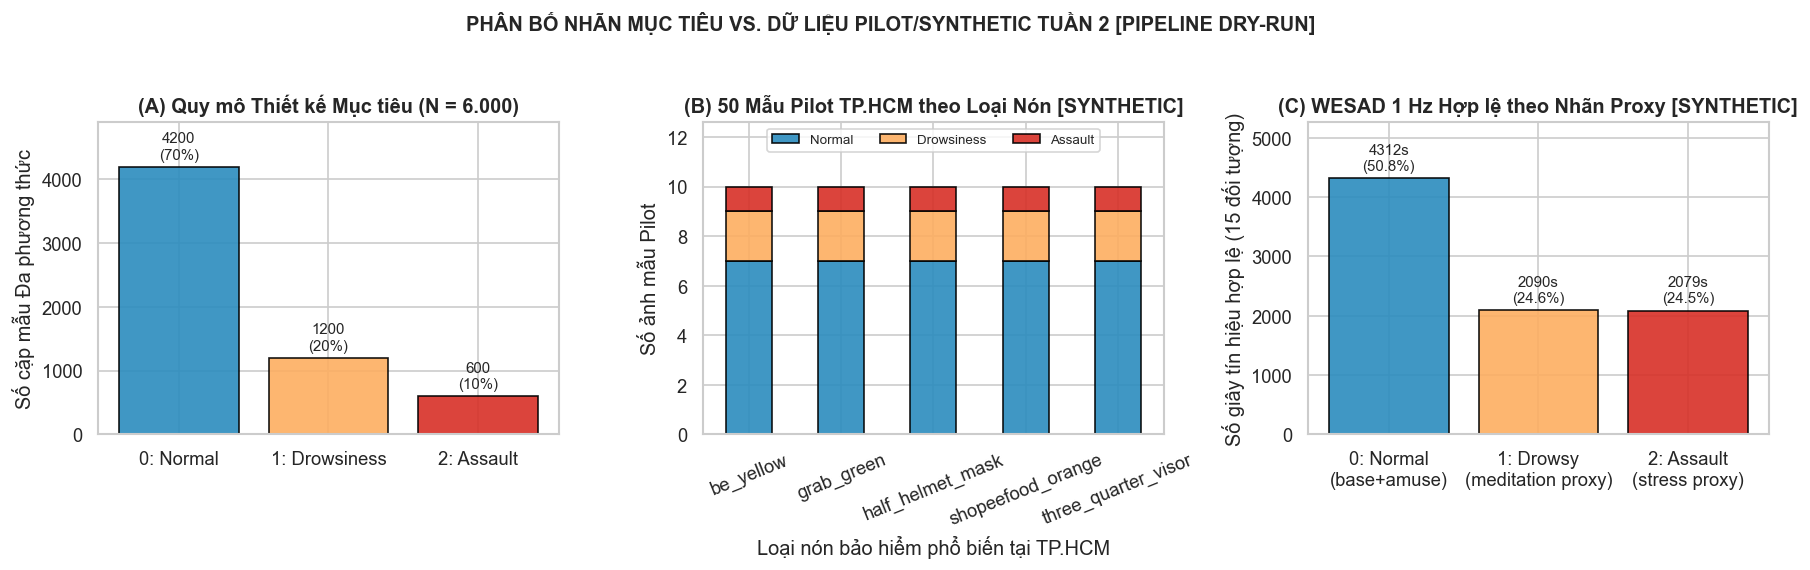

Saved figure -> D:\Trí tuệ nhân tạo\HK3\Máy học nâng cao\Đồ án\reports\figures\week2_eda_class_distribution.png


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), dpi=120)
fig.suptitle(
    "PHÂN BỐ NHÃN MỤC TIÊU VS. DỮ LIỆU PILOT/SYNTHETIC TUẦN 2 [PIPELINE DRY-RUN]",
    fontsize=12,
    fontweight="bold",
    y=1.03,
)

palette_3c = ["#2b8cbe", "#fdae61", "#d73027"]
class_labels = ["0: Normal", "1: Drowsiness", "2: Assault"]

# Panel A: Thiết kế mục tiêu N = 6,000
target_counts = [4200, 1200, 600]
bars_a = axes[0].bar(class_labels, target_counts, color=palette_3c, edgecolor="black", alpha=0.9)
axes[0].set_title("(A) Quy mô Thiết kế Mục tiêu (N = 6.000)", fontweight="bold")
axes[0].set_ylabel("Số cặp mẫu Đa phương thức")
for b, cnt in zip(bars_a, target_counts):
    axes[0].text(
        b.get_x() + b.get_width() / 2,
        cnt + 80,
        f"{cnt}\n({cnt / 6000:.0%})",
        ha="center",
        va="bottom",
        fontsize=9,
    )
axes[0].set_ylim(0, 4900)

# Panel B: 50 mẫu Pilot Nón bảo hiểm TP.HCM theo loại nón & lớp
ct_helmet = pd.crosstab(pilot_df["helmet_type"], pilot_df["class_name"])[
    ["Normal", "Drowsiness", "Assault"]
]
ct_helmet.plot(
    kind="bar",
    stacked=True,
    ax=axes[1],
    color=palette_3c,
    edgecolor="black",
    alpha=0.9,
)
axes[1].set_title("(B) 50 Mẫu Pilot TP.HCM theo Loại Nón [SYNTHETIC]", fontweight="bold")
axes[1].set_xlabel("Loại nón bảo hiểm phổ biến tại TP.HCM")
axes[1].set_ylabel("Số ảnh mẫu Pilot")
axes[1].set_ylim(0, 12.6)
axes[1].tick_params(axis="x", rotation=22)
axes[1].legend(title=None, loc="upper center", ncol=3, fontsize=8, frameon=True)

# Panel C: Phân bố giây hợp lệ trên WESAD Synthetic theo nhãn Proxy
valid_bio = bio_df[bio_df["is_valid"] & (bio_df["project_label"] >= 0)]
bio_counts_s = valid_bio["project_label"].value_counts().reindex([0, 1, 2], fill_value=0)
bars_c = axes[2].bar(
    ["0: Normal\n(base+amuse)", "1: Drowsy\n(meditation proxy)", "2: Assault\n(stress proxy)"],
    bio_counts_s.values,
    color=palette_3c,
    edgecolor="black",
    alpha=0.9,
)
axes[2].set_title("(C) WESAD 1 Hz Hợp lệ theo Nhãn Proxy [SYNTHETIC]", fontweight="bold")
axes[2].set_ylabel("Số giây tín hiệu hợp lệ (15 đối tượng)")
total_vb = int(bio_counts_s.sum())
for b, cnt in zip(bars_c, bio_counts_s.values):
    axes[2].text(
        b.get_x() + b.get_width() / 2,
        cnt + 90,
        f"{cnt}s\n({cnt / total_vb:.1%})",
        ha="center",
        va="bottom",
        fontsize=9,
    )
axes[2].set_ylim(0, max(bio_counts_s.values) * 1.22)

plt.tight_layout()
out_dist = FIGURES_DIR / "week2_eda_class_distribution.png"
fig.savefig(out_dist, bbox_inches="tight")
plt.show()
print(f"Saved figure -> {out_dist}")

## 3. Kiểm tra Trực quan Mẫu Pilot Nón bảo hiểm TP.HCM & Phân tích Độ sáng / Góc gục đầu

Bộ 50 ảnh mẫu pilot (`data/raw/local_samples_synthetic/manifest.csv`) kiểm tra đầy đủ các trường metadata bắt buộc của kế hoạch thu thập thực địa TP.HCM: `helmet_type`, `lighting_condition`, `occlusion_type`, `head_pitch_deg_est` và `subject_id`.

=== THỐNG KÊ ĐỘ SÁNH TRUNG BÌNH THEO ĐIỀU KIỆN ÁNH SÁNG (0-255) ===
  - daylight_sunny    : 159.86
  - dusk_streetlight  :  93.44
  - night_glare       :  67.09
  - tree_shadow       : 116.25

=== GÓC NGHIÊNG ĐẦU ƯỚC LƯỢNG TRUNG BÌNH THEO PHÂN LỚP (ĐỘ) ===
  - Normal      : 10.49 deg
  - Drowsiness  : 34.34 deg
  - Assault     : 12.97 deg


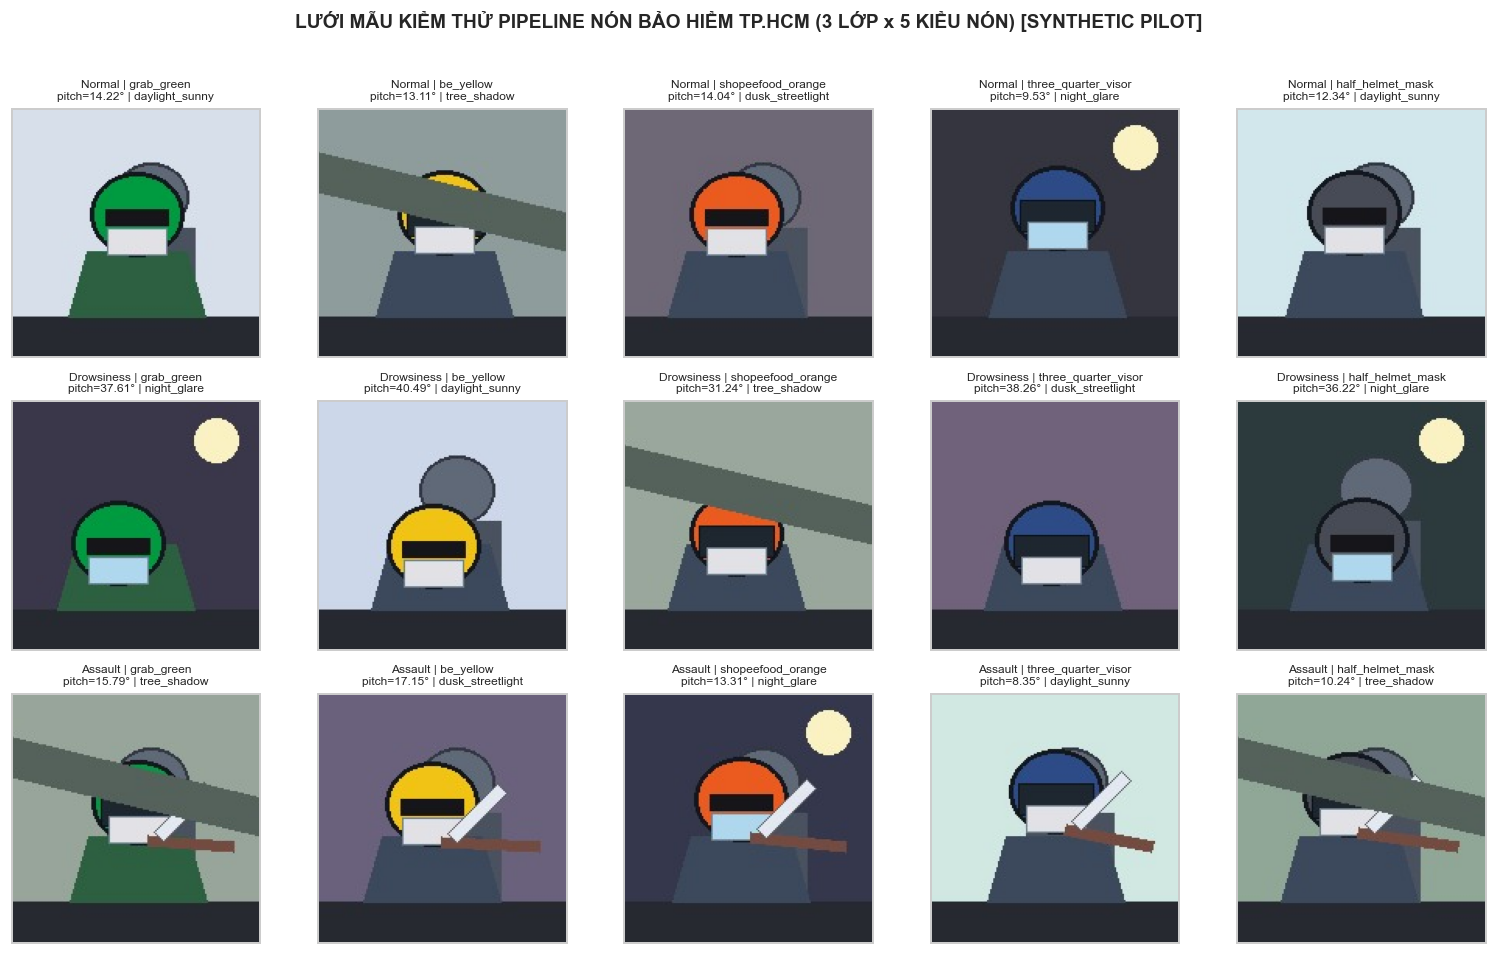

Saved figure -> D:\Trí tuệ nhân tạo\HK3\Máy học nâng cao\Đồ án\reports\figures\week2_eda_local_helmet_grid.png


In [4]:
print("=== THỐNG KÊ ĐỘ SÁNH TRUNG BÌNH THEO ĐIỀU KIỆN ÁNH SÁNG (0-255) ===")
for cond, luma in pilot_val["mean_brightness_by_lighting"].items():
    print(f"  - {cond:<18s}: {luma:6.2f}")

print("\n=== GÓC NGHIÊNG ĐẦU ƯỚC LƯỢNG TRUNG BÌNH THEO PHÂN LỚP (ĐỘ) ===")
for cname, pitch in pilot_val["mean_head_pitch_deg_by_class"].items():
    print(f"  - {cname:<12s}: {pitch:5.2f} deg")

# Hiển thị lưới 3 hàng (Normal, Drowsiness, Assault) x 5 cột (5 kiểu nón bảo hiểm VN)
fig, axes = plt.subplots(3, 5, figsize=(13.5, 8.2), dpi=115)
fig.suptitle(
    "LƯỚI MẪU KIỂM THỬ PIPELINE NÓN BẢO HIỂM TP.HCM (3 LỚP x 5 KIỂU NÓN) [SYNTHETIC PILOT]",
    fontsize=12,
    fontweight="bold",
    y=1.01,
)

helmet_order = [
    "grab_green",
    "be_yellow",
    "shopeefood_orange",
    "three_quarter_visor",
    "half_helmet_mask",
]

for row_cls, cls_name in enumerate(["Normal", "Drowsiness", "Assault"]):
    sub_cls = pilot_df[pilot_df["class_label"] == row_cls]
    for col_idx, h_type in enumerate(helmet_order):
        ax = axes[row_cls, col_idx]
        cand = sub_cls[sub_cls["helmet_type"] == h_type]
        if len(cand) == 0:
            cand = sub_cls.iloc[[col_idx % len(sub_cls)]]
        rec = cand.iloc[0]
        img = Image.open(SYNTHETIC_LOCAL_SAMPLES_DIR / rec["file_name"])
        ax.imshow(img)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(
            f"{cls_name} | {rec['helmet_type']}\npitch={rec['head_pitch_deg_est']}° | {rec['lighting_condition']}",
            fontsize=7.5,
        )

plt.tight_layout()
out_grid = FIGURES_DIR / "week2_eda_local_helmet_grid.png"
fig.savefig(out_grid, bbox_inches="tight")
plt.show()
print(f"Saved figure -> {out_grid}")

## 4. Khám phá Chuỗi thời gian Nhịp tim 1 Hz & Cờ Nhiễu (`is_dropout`, `is_motion`)

Kiểm tra trực quan đầu ra của `src/data/parse_wesad.py` trên đối tượng mẫu `S2` và phân phối nhịp tim qua 15 đối tượng tổng hợp. Lưu ý: trật tự nhịp tim `stress > amusement > baseline > meditation` dưới đây phản ánh đúng tham số thiết kế của bộ sinh synthetic (kiểm chứng bộ trích xuất đỉnh BVP $\rightarrow$ IBI $\rightarrow$ HR 1 Hz không làm méo trật tự sinh lý và gắn cờ chính xác các đoạn mất tín hiệu).

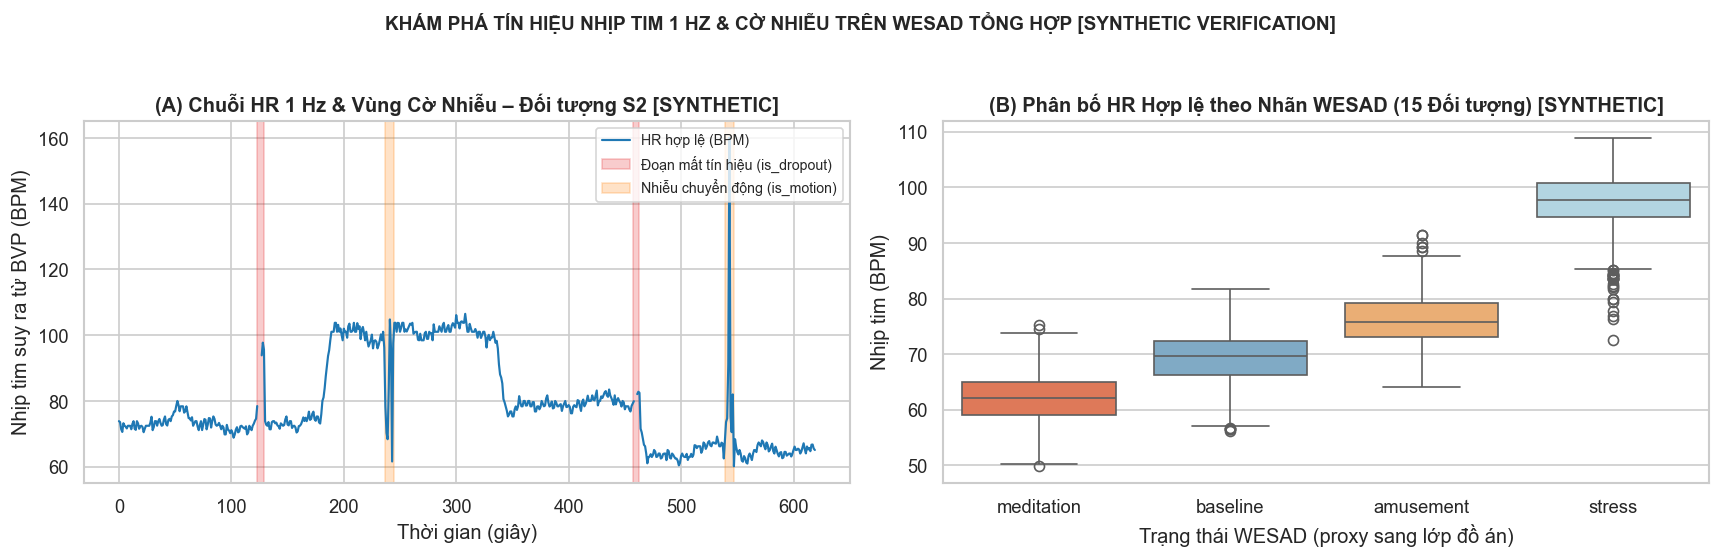

Saved figure -> D:\Trí tuệ nhân tạo\HK3\Máy học nâng cao\Đồ án\reports\figures\week2_eda_bio_hr_profile.png


In [5]:
s2 = bio_df[bio_df["subject"] == "S2"].sort_values("t_sec")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.5), dpi=120)
fig.suptitle(
    "KHÁM PHÁ TÍN HIỆU NHỊP TIM 1 HZ & CỜ NHIỄU TRÊN WESAD TỔNG HỢP [SYNTHETIC VERIFICATION]",
    fontsize=11.5,
    fontweight="bold",
    y=1.03,
)

# Panel A: Chuỗi thời gian HR 1 Hz của đối tượng S2 và toàn bộ các vùng gắn cờ nhiễu
def _contiguous_spans(t_arr, mask_arr):
    spans = []
    in_span = False
    start_t = 0
    for t_val, flag in zip(t_arr, mask_arr):
        if flag and not in_span:
            start_t = int(t_val)
            in_span = True
        elif not flag and in_span:
            spans.append((start_t, int(t_val)))
            in_span = False
    if in_span:
        spans.append((start_t, int(t_arr[-1]) + 1))
    return spans

axes[0].plot(s2["t_sec"], s2["hr_bpm"], color="#1f78b4", linewidth=1.3, label="HR hợp lệ (BPM)")
t_vals = s2["t_sec"].to_numpy()
for idx_s, (a, b) in enumerate(_contiguous_spans(t_vals, s2["is_dropout"].astype(bool).to_numpy())):
    axes[0].axvspan(
        a, b, color="#e31a1c", alpha=0.22,
        label="Đoạn mất tín hiệu (is_dropout)" if idx_s == 0 else None,
    )
for idx_s, (a, b) in enumerate(_contiguous_spans(t_vals, s2["is_motion"].astype(bool).to_numpy())):
    axes[0].axvspan(
        a, b, color="#ff7f00", alpha=0.22,
        label="Nhiễu chuyển động (is_motion)" if idx_s == 0 else None,
    )
axes[0].set_title("(A) Chuỗi HR 1 Hz & Vùng Cờ Nhiễu – Đối tượng S2 [SYNTHETIC]", fontweight="bold")
axes[0].set_xlabel("Thời gian (giây)")
axes[0].set_ylabel("Nhịp tim suy ra từ BVP (BPM)")
axes[0].legend(loc="upper right", fontsize=8.5)

# Panel B: Boxplot phân bố HR hợp lệ theo trạng thái WESAD (15 đối tượng synthetic)
valid_states = bio_df[bio_df["is_valid"] & bio_df["label_name"].isin(["meditation", "baseline", "amusement", "stress"])]
sns.boxplot(
    data=valid_states,
    x="label_name",
    y="hr_bpm",
    order=["meditation", "baseline", "amusement", "stress"],
    hue="label_name",
    palette=["#74add1", "#abd9e9", "#fdae61", "#f46d43"],
    legend=False,
    ax=axes[1],
)
axes[1].set_title("(B) Phân bố HR Hợp lệ theo Nhãn WESAD (15 Đối tượng) [SYNTHETIC]", fontweight="bold")
axes[1].set_xlabel("Trạng thái WESAD (proxy sang lớp đồ án)")
axes[1].set_ylabel("Nhịp tim (BPM)")

plt.tight_layout()
out_bio = FIGURES_DIR / "week2_eda_bio_hr_profile.png"
fig.savefig(out_bio, bbox_inches="tight")
plt.show()
print(f"Saved figure -> {out_bio}")

## 5. Điểm neo Mở rộng cho Tuần 3 (Data Augmentation & Stratified Subject-Independent 5-Fold)

Khung Notebook EDA Tuần 2 đã xác nhận cấu trúc dữ liệu đồng bộ cho cả 3 nguồn. Trong **Tuần 3 (02/11 – 08/11/2026)**, Notebook này sẽ được mở rộng thêm 3 mục trực quan hóa tiếp theo:
1. **Tiền xử lý & Tăng cường Thị giác (`src/data/vision_transforms.py`):** Đối chiếu ảnh gốc $160 \times 160$ và ảnh chuẩn hóa $3 \times 96 \times 96$ qua `MotionBlur`, `RandomBrightnessContrast`, `RandomShadow` và `Perspective`.
2. **Tiền xử lý Chuỗi thời gian (`src/data/bio_transforms.py`):** Đối chiếu phổ tần số và dạng sóng PPG trước/sau bộ lọc thông dải Butterworth ($0.5 - 4.0$ Hz) và cắt cửa sổ trượt $T = 30$ giây.
3. **Kiểm định Chia tập Không rò rỉ Đối tượng (`splits_5fold.json`):** Xác nhận $0\%$ giao thoa `subject_id` giữa tập Train và Validation trên toàn bộ 5 Folds.